# Cost-Aware Conformal Deferral Framework Evaluation

This notebook evaluates the proposed innovation:

**Cost-Aware Conformal Deferral Framework**

It compares three decision policies:

1. **No Deferral** — the model always predicts.
2. **Confidence-Only Deferral** — defer if confidence is below `tau`.
3. **Conformal-Aware Deferral** — defer if confidence is below `tau` **or** the conformal prediction set is ambiguous.

The goal is to evaluate whether integrating conformal set ambiguity directly into the deferral rule improves safety and cost-aware decision quality.


## 1. Imports and configuration

Update the `MODEL_CONFIGS` paths to point to your latest experiment folders if needed.

Each experiment folder should contain:

- `full_pipeline_results.json`
- `step9_test_predictions.csv`
- optionally `step7_deferral_search.csv`


In [11]:
import os
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

OUTPUT_DIR = Path("cost_aware_conformal_deferral_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

MODEL_CONFIGS = {
    "RandomForest": {
        "run_dir": "experiments_rf/run_2026-05-20_13-27-11",  # e.g. "experiments_rf/run_2026-05-10_12-00-00"
        "results_json": "experiments_rf/run_2026-05-20_13-27-11/full_pipeline_results.json"
    },
    "RUSBoost": {
        "run_dir": "experiments_rusboost/run_2026-05-20_13-28-56",  # e.g. "experiments_rusboost/run_2026-05-10_12-00-00"
        "results_json": "experiments_rusboost/run_2026-05-20_13-28-56/full_pipeline_results.json"
    },
    "XGBoost": {
        "run_dir": "experiments_xgboost/run_2026-05-20_13-29-57",  # e.g. "experiments_xgboost/run_2026-05-10_12-00-00"
        "results_json": "experiments_xgboost/run_2026-05-20_13-29-57/full_pipeline_results.json"
    }
}

COSTS = {
    "c_fn": 20.0,
    "c_fp": 1.0,
    "c_def": 2.0
}

TAU_GRID = np.linspace(0.50, 0.99, 100)


## 2. Helper functions

These functions normalize different result JSON schemas, load artifacts, and evaluate the three policies.


In [12]:
def load_json(path):
    with open(path, "r") as f:
        return json.load(f)


def normalize_results_schema(res):
    """
    Makes older RF/RUS/XGB result JSON files comparable.
    """
    normalized = dict(res)

    if "step6_conformal" in normalized and "step6_conformal_calibration" not in normalized:
        normalized["step6_conformal_calibration"] = normalized["step6_conformal"]

    if "step7_deferral" in normalized and "step7_deferral_tuning" not in normalized:
        normalized["step7_deferral_tuning"] = normalized["step7_deferral"]

    if "step9_final" in normalized and "step9_final_evaluation" not in normalized:
        normalized["step9_final_evaluation"] = normalized["step9_final"]

    return normalized


def locate_artifact(model_name, cfg, artifact_name):
    """
    Tries to locate a CSV artifact from:
    1. run_dir
    2. artifact_paths inside results JSON
    """
    run_dir = cfg.get("run_dir")
    if run_dir:
        path = Path(run_dir) / f"{artifact_name}.csv"
        if path.exists():
            return path

    results_json = Path(cfg["results_json"])
    if results_json.exists():
        res = normalize_results_schema(load_json(results_json))
        artifact_paths = res.get("artifact_paths", {})
        if artifact_name in artifact_paths:
            path = Path(artifact_paths[artifact_name])
            if path.exists():
                return path

    return None


def get_base_threshold(res):
    """
    Reads the class threshold chosen in Step 4.
    """
    res = normalize_results_schema(res)

    if "step4_thresholding" in res:
        return float(res["step4_thresholding"]["base_threshold"])

    if "threshold" in res:
        return float(res["threshold"])

    raise KeyError(
        "Missing step4_thresholding/base_threshold. "
        "Rerun the model after adding step4_thresholding to results."
    )


def evaluate_policy_from_df(df, base_threshold, tau, policy_name, c_fn, c_fp, c_def):
    """
    Evaluates one policy from saved test prediction rows.

    Required columns:
    - y_true
    - p1
    - certainty
    - cp_set_size
    """
    y_true = df["y_true"].astype(int).to_numpy()
    p1 = df["p1"].astype(float).to_numpy()

    if "certainty" in df.columns:
        certainty = df["certainty"].astype(float).to_numpy()
    else:
        p0 = df["p0"].astype(float).to_numpy()
        certainty = np.maximum(p0, p1)

    if "cp_set_size" in df.columns:
        cp_set_size = df["cp_set_size"].astype(int).to_numpy()
    else:
        raise KeyError("Missing cp_set_size in step9_test_predictions.csv")

    pred = (p1 >= base_threshold).astype(int)

    if policy_name == "No Deferral":
        defer_mask = np.zeros(len(df), dtype=bool)
    elif policy_name == "Confidence-Only Deferral":
        defer_mask = certainty < tau
    elif policy_name == "Conformal-Aware Deferral":
        defer_mask = (certainty < tau) | (cp_set_size != 1)
    else:
        raise ValueError(f"Unknown policy: {policy_name}")

    retained = ~defer_mask

    fn = int(((pred == 0) & (y_true == 1) & retained).sum())
    fp = int(((pred == 1) & (y_true == 0) & retained).sum())
    tp = int(((pred == 1) & (y_true == 1) & retained).sum())
    tn = int(((pred == 0) & (y_true == 0) & retained).sum())
    deferred = int(defer_mask.sum())

    total_cost = (c_fn * fn) + (c_fp * fp) + (c_def * deferred)
    cost_per_sample = total_cost / len(df)

    if retained.sum() > 0:
        retained_error = float((pred[retained] != y_true[retained]).mean())
        retained_recall = float(
            ((pred == 1) & (y_true == 1) & retained).sum()
            / max(((y_true == 1) & retained).sum(), 1)
        )
        retained_precision = float(
            ((pred == 1) & (y_true == 1) & retained).sum()
            / max(((pred == 1) & retained).sum(), 1)
        )
    else:
        retained_error = np.nan
        retained_recall = np.nan
        retained_precision = np.nan

    return {
        "policy": policy_name,
        "tau": float(tau),
        "coverage": float(retained.mean()),
        "deferred_fraction": float(defer_mask.mean()),
        "deferred_count": deferred,
        "retained_error": retained_error,
        "retained_recall": retained_recall,
        "retained_precision": retained_precision,
        "fn": fn,
        "fp": fp,
        "tp": tp,
        "tn": tn,
        "total_cost": float(total_cost),
        "cost_per_sample": float(cost_per_sample)
    }


def tune_policy(df, base_threshold, policy_name, tau_grid, costs):
    """
    Searches tau and returns all rows plus best row.
    """
    if policy_name == "No Deferral":
        row = evaluate_policy_from_df(
            df=df,
            base_threshold=base_threshold,
            tau=0.0,
            policy_name=policy_name,
            **costs
        )
        return pd.DataFrame([row]), row

    rows = [
        evaluate_policy_from_df(
            df=df,
            base_threshold=base_threshold,
            tau=tau,
            policy_name=policy_name,
            **costs
        )
        for tau in tau_grid
    ]

    search_df = pd.DataFrame(rows)
    best_row = (
        search_df
        .sort_values(["cost_per_sample", "deferred_fraction"], ascending=[True, True])
        .iloc[0]
        .to_dict()
    )

    return search_df, best_row


## 3. Load model outputs

This cell expects the saved test prediction CSVs from your model pipeline.

If a model fails here, rerun that model after adding artifact saving for `step9_test_predictions.csv`.


In [13]:
loaded = {}

for model_name, cfg in MODEL_CONFIGS.items():
    results_path = Path(cfg["results_json"])
    if not results_path.exists():
        print(f"Skipping {model_name}: results JSON not found -> {results_path}")
        continue

    results = normalize_results_schema(load_json(results_path))

    try:
        base_threshold = get_base_threshold(results)
    except KeyError as e:
        print(f"Skipping {model_name}: {e}")
        continue

    test_csv = locate_artifact(model_name, cfg, "step9_test_predictions")

    if test_csv is None:
        print(f"Skipping {model_name}: step9_test_predictions.csv not found.")
        print("Set run_dir correctly or rerun the model so artifact_paths contains step9_test_predictions.")
        continue

    test_df = pd.read_csv(test_csv)

    loaded[model_name] = {
        "results": results,
        "base_threshold": base_threshold,
        "test_df": test_df,
        "test_csv": str(test_csv)
    }

    print(f"Loaded {model_name}")
    print(f"  base_threshold: {base_threshold}")
    print(f"  test_csv: {test_csv}")
    print(f"  rows: {len(test_df)}")

print("\nModels loaded:", list(loaded.keys()))


Loaded RandomForest
  base_threshold: 0.03474747474747475
  test_csv: experiments_rf/run_2026-05-20_13-27-11/step9_test_predictions.csv
  rows: 2000
Loaded RUSBoost
  base_threshold: 0.03474747474747475
  test_csv: experiments_rusboost/run_2026-05-20_13-28-56/step9_test_predictions.csv
  rows: 2000
Loaded XGBoost
  base_threshold: 0.014949494949494949
  test_csv: experiments_xgboost/run_2026-05-20_13-29-57/step9_test_predictions.csv
  rows: 2000

Models loaded: ['RandomForest', 'RUSBoost', 'XGBoost']


 ## 4. Evaluate three policies

Policies:

1. **No Deferral**
2. **Confidence-Only Deferral**
3. **Conformal-Aware Deferral** ← proposed innovation


In [14]:
all_policy_search_rows = []
best_policy_rows = []

POLICIES = [
    "No Deferral",
    "Confidence-Only Deferral",
    "Conformal-Aware Deferral"
]

for model_name, obj in loaded.items():
    test_df = obj["test_df"]
    base_threshold = obj["base_threshold"]

    for policy in POLICIES:
        search_df, best = tune_policy(
            df=test_df,
            base_threshold=base_threshold,
            policy_name=policy,
            tau_grid=TAU_GRID,
            costs=COSTS
        )

        search_df["model"] = model_name
        best["model"] = model_name

        all_policy_search_rows.append(search_df)
        best_policy_rows.append(best)

if not best_policy_rows:
    raise RuntimeError("No model outputs were loaded. Check MODEL_CONFIGS and rerun after saving step9_test_predictions.csv.")

policy_search_df = pd.concat(all_policy_search_rows, ignore_index=True)
best_policy_df = pd.DataFrame(best_policy_rows)

front_cols = ["model", "policy", "tau", "coverage", "deferred_fraction", "retained_error",
              "retained_recall", "retained_precision", "fn", "fp", "deferred_count",
              "total_cost", "cost_per_sample"]

best_policy_df = best_policy_df[front_cols]
policy_search_df = policy_search_df[front_cols]

policy_search_path = OUTPUT_DIR / "policy_search_all_models.csv"
best_policy_path = OUTPUT_DIR / "best_policy_comparison.csv"

policy_search_df.to_csv(policy_search_path, index=False)
best_policy_df.to_csv(best_policy_path, index=False)

print("Saved:", policy_search_path)
print("Saved:", best_policy_path)

display(best_policy_df.sort_values(["model", "cost_per_sample"]))


Saved: cost_aware_conformal_deferral_outputs/policy_search_all_models.csv
Saved: cost_aware_conformal_deferral_outputs/best_policy_comparison.csv


,model,policy,tau,coverage,deferred_fraction,retained_error,retained_recall,retained_precision,fn,fp,deferred_count,total_cost,cost_per_sample
3,RUSBoost,No Deferral,0.0,1.000,0.000,0.080500,0.926471,0.287671,5,156,0,256.0,0.1280
4,RUSBoost,Confidence-Only Deferral,0.5,1.000,0.000,0.080500,0.926471,0.287671,5,156,0,256.0,0.1280
5,RUSBoost,Conformal-Aware Deferral,0.5,0.941,0.059,0.047821,0.761905,0.158416,5,85,118,421.0,0.2105
0,RandomForest,No Deferral,0.0,1.000,0.000,0.085500,0.911765,0.273128,6,165,0,285.0,0.1425
1,RandomForest,Confidence-Only Deferral,0.5,1.000,0.000,0.085500,0.911765,0.273128,6,165,0,285.0,0.1425
2,RandomForest,Conformal-Aware Deferral,0.5,0.941,0.059,0.046227,0.823529,0.256881,6,81,118,437.0,0.2185
6,XGBoost,No Deferral,0.0,1.000,0.000,0.088500,0.911765,0.266094,6,171,0,291.0,0.1455
7,XGBoost,Confidence-Only Deferral,0.5,1.000,0.000,0.088500,0.911765,0.266094,6,171,0,291.0,0.1455
8,XGBoost,Conformal-Aware Deferral,0.5,0.925,0.075,0.042703,0.625000,0.120482,6,73,150,493.0,0.2465


## 5. Main comparison table

This is the table you can use in your results section.

The proposed method should be judged by whether it reduces cost and dangerous retained errors, even if it defers more cases.


In [15]:
summary = (
    best_policy_df
    .sort_values(["model", "cost_per_sample"])
    .reset_index(drop=True)
)

display(summary)

best_per_model = (
    best_policy_df
    .sort_values(["model", "cost_per_sample"])
    .groupby("model", as_index=False)
    .first()
)

display(best_per_model)

best_per_model.to_csv(OUTPUT_DIR / "best_policy_per_model.csv", index=False)


,model,policy,tau,coverage,deferred_fraction,retained_error,retained_recall,retained_precision,fn,fp,deferred_count,total_cost,cost_per_sample
0,RUSBoost,No Deferral,0.0,1.000,0.000,0.080500,0.926471,0.287671,5,156,0,256.0,0.1280
1,RUSBoost,Confidence-Only Deferral,0.5,1.000,0.000,0.080500,0.926471,0.287671,5,156,0,256.0,0.1280
2,RUSBoost,Conformal-Aware Deferral,0.5,0.941,0.059,0.047821,0.761905,0.158416,5,85,118,421.0,0.2105
3,RandomForest,No Deferral,0.0,1.000,0.000,0.085500,0.911765,0.273128,6,165,0,285.0,0.1425
4,RandomForest,Confidence-Only Deferral,0.5,1.000,0.000,0.085500,0.911765,0.273128,6,165,0,285.0,0.1425
5,RandomForest,Conformal-Aware Deferral,0.5,0.941,0.059,0.046227,0.823529,0.256881,6,81,118,437.0,0.2185
6,XGBoost,No Deferral,0.0,1.000,0.000,0.088500,0.911765,0.266094,6,171,0,291.0,0.1455
7,XGBoost,Confidence-Only Deferral,0.5,1.000,0.000,0.088500,0.911765,0.266094,6,171,0,291.0,0.1455
8,XGBoost,Conformal-Aware Deferral,0.5,0.925,0.075,0.042703,0.625000,0.120482,6,73,150,493.0,0.2465


,model,policy,tau,coverage,deferred_fraction,retained_error,retained_recall,retained_precision,fn,fp,deferred_count,total_cost,cost_per_sample
0,RUSBoost,No Deferral,0.0,1.0,0.0,0.0805,0.926471,0.287671,5,156,0,256.0,0.1280
1,RandomForest,No Deferral,0.0,1.0,0.0,0.0855,0.911765,0.273128,6,165,0,285.0,0.1425
2,XGBoost,No Deferral,0.0,1.0,0.0,0.0885,0.911765,0.266094,6,171,0,291.0,0.1455


## 6. Plot: Cost per sample by policy

Lower is better.


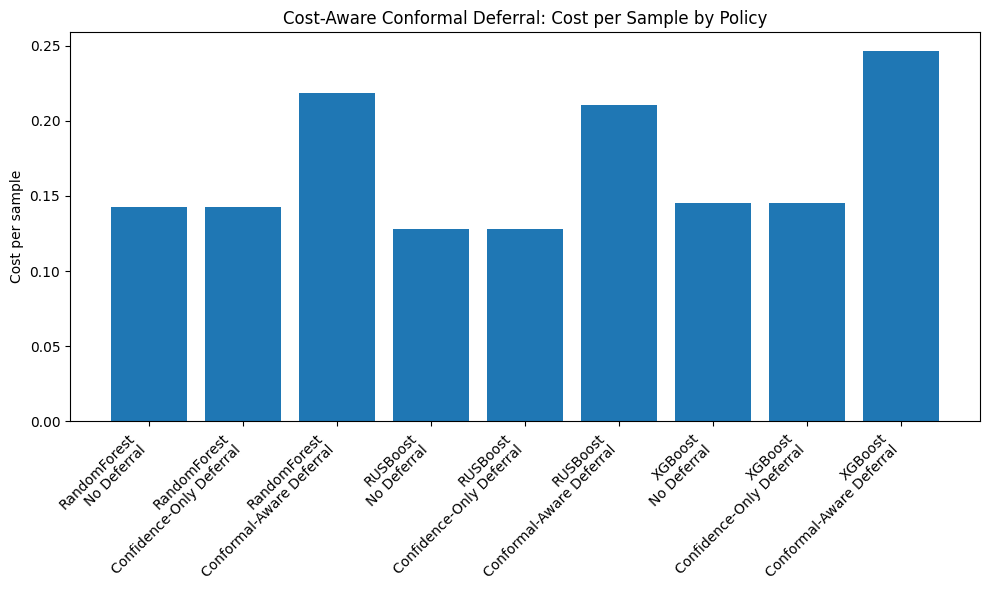

Saved: cost_aware_conformal_deferral_outputs/cost_per_sample_by_policy.png


In [16]:
plt.figure(figsize=(10, 6))

x_labels = best_policy_df["model"] + "\n" + best_policy_df["policy"]
plt.bar(x_labels, best_policy_df["cost_per_sample"])

plt.xticks(rotation=45, ha="right")
plt.ylabel("Cost per sample")
plt.title("Cost-Aware Conformal Deferral: Cost per Sample by Policy")
plt.tight_layout()

plot_path = OUTPUT_DIR / "cost_per_sample_by_policy.png"
plt.savefig(plot_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", plot_path)


## 7. Plot: Coverage vs cost

This visualizes the risk/cost–coverage trade-off.

A good policy should achieve low cost while retaining useful coverage.


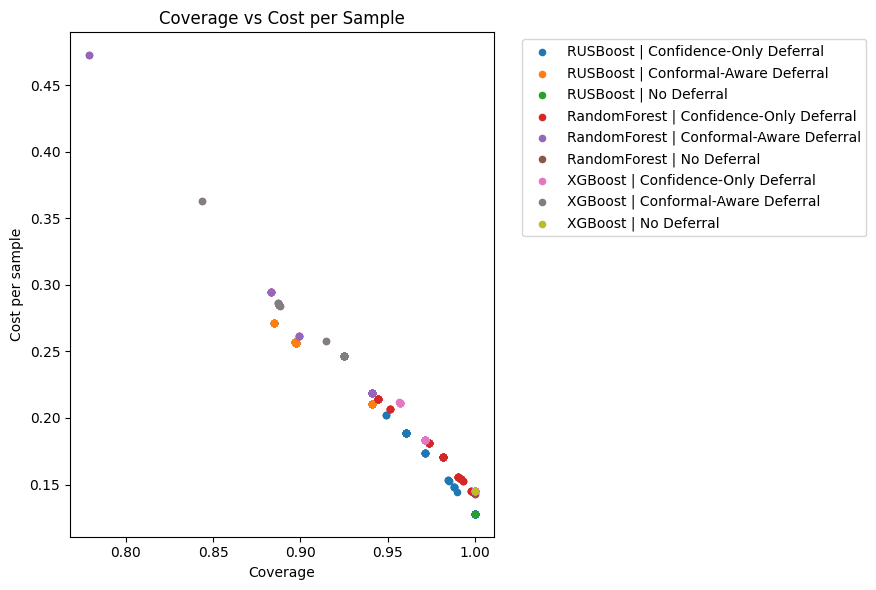

Saved: cost_aware_conformal_deferral_outputs/coverage_vs_cost.png


In [17]:
plt.figure(figsize=(9, 6))

for (model, policy), group in policy_search_df.groupby(["model", "policy"]):
    plt.scatter(group["coverage"], group["cost_per_sample"], label=f"{model} | {policy}", s=20)

plt.xlabel("Coverage")
plt.ylabel("Cost per sample")
plt.title("Coverage vs Cost per Sample")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()

plot_path = OUTPUT_DIR / "coverage_vs_cost.png"
plt.savefig(plot_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", plot_path)


## 8. Plot: Deferred fraction by policy

This shows how much work is sent for inspection/manual review.


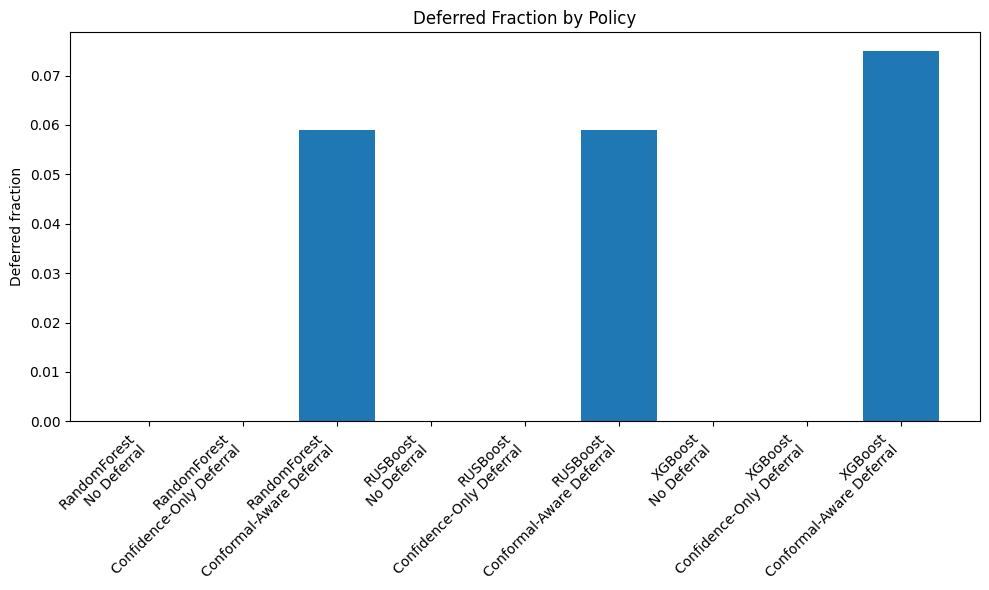

Saved: cost_aware_conformal_deferral_outputs/deferred_fraction_by_policy.png


In [18]:
plt.figure(figsize=(10, 6))

x_labels = best_policy_df["model"] + "\n" + best_policy_df["policy"]
plt.bar(x_labels, best_policy_df["deferred_fraction"])

plt.xticks(rotation=45, ha="right")
plt.ylabel("Deferred fraction")
plt.title("Deferred Fraction by Policy")
plt.tight_layout()

plot_path = OUTPUT_DIR / "deferred_fraction_by_policy.png"
plt.savefig(plot_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", plot_path)


## 9. Interpreting the proposed innovation

Use the comparison between **Confidence-Only Deferral** and **Conformal-Aware Deferral**.

Your novelty is supported if Conformal-Aware Deferral:

- reduces `cost_per_sample`, or
- reduces false negatives among retained predictions, or
- reduces retained error, or
- improves retained recall,

while keeping coverage at a reasonable level.


In [20]:
innovation_comparison = best_policy_df[
    best_policy_df["policy"].isin(["Confidence-Only Deferral", "Conformal-Aware Deferral"])
].copy()

pivot = innovation_comparison.pivot(index="model", columns="policy", values=[
    "cost_per_sample", "coverage", "deferred_fraction", "retained_error", "retained_recall", "fn"
])

display(pivot)

pivot.to_csv(OUTPUT_DIR / "innovation_confidence_vs_conformal_aware.csv")


cost_per_sample                           \
policy       Confidence-Only Deferral Conformal-Aware Deferral   
model                                                            
RUSBoost                       0.1280                   0.2105   
RandomForest                   0.1425                   0.2185   
XGBoost                        0.1455                   0.2465   

                             coverage                           \
policy       Confidence-Only Deferral Conformal-Aware Deferral   
model                                                            
RUSBoost                          1.0                    0.941   
RandomForest                      1.0                    0.941   
XGBoost                           1.0                    0.925   

                    deferred_fraction                           \
policy       Confidence-Only Deferral Conformal-Aware Deferral   
model                                                            
RUSBoost                          0.0                    0.059   
RandomForest                      0.0                    0.059   
XGBoost                           0.0                    0.075   

                       retained_error                           \
policy       Confidence-Only Deferral Conformal-Aware Deferral   
model                                                            
RUSBoost                       0.0805                 0.047821   
RandomForest                   0.0855                 0.046227   
XGBoost                        0.0885                 0.042703   

                      retained_recall                           \
policy       Confidence-Only Deferral Conformal-Aware Deferral   
model                                                            
RUSBoost                     0.926471                 0.761905   
RandomForest                 0.911765                 0.823529   
XGBoost                      0.911765                 0.625000   

                                   fn                           
policy       Confidence-Only Deferral Conformal-Aware Deferral  
model                                                           
RUSBoost                          5.0                      5.0  
RandomForest                      6.0                      6.0  
XGBoost                           6.0                      6.0

## 10. Suggested thesis statement

> The proposed Cost-Aware Conformal Deferral Framework improves safety-aware predictive maintenance by converting conformal prediction from a passive uncertainty reporting tool into an active decision gate. The framework defers cases that are either low-confidence or conformally ambiguous, allowing the system to balance automated coverage, expected maintenance cost, and retained prediction reliability.
